<a href="https://colab.research.google.com/github/siva567-pixel/DSA_Exit_Exam/blob/main/G1_DSA_Exit_Exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [246]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

Task 1: Data Understanding & Exploration

LOAD

In [247]:
df = pd.read_csv('/content/drive/MyDrive/DSA/Exit test/G1 (1).csv')

In [248]:
FILE = "G1 (1).csv"
TARGET = "Best_Shopping_Mode"

EDA

In [249]:
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [250]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [251]:
df.describe()

,Response_ID,Review_Influence_Score,Social_Ads_Influence_Score,Price_Comparison_Frequency,Discount_Importance_Score,Likely_To_Buy_After_Ad_Score,Impulse_Purchase_Frequency,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency
count,500.000000,485.000000,479.000000,474.000000,477.000000,475.000000,484.000000,457.000000,450.000000,448.000000
mean,250.500000,3.053608,3.079332,4.139241,3.821803,3.016842,2.590909,7.126915,6.160000,2.187500
std,144.481833,1.128707,1.228144,0.943219,0.989284,1.109857,1.162741,1.592636,1.918425,0.902705
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000
25%,125.750000,2.000000,2.000000,4.000000,3.000000,2.000000,2.000000,6.000000,5.000000,1.000000
50%,250.500000,3.000000,3.000000,4.000000,4.000000,3.000000,2.000000,7.000000,6.000000,2.000000
75%,375.250000,4.000000,4.000000,5.000000,5.000000,4.000000,3.000000,8.000000,7.000000,3.000000
max,500.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,10.000000,10.000000,4.000000


In [252]:
df.shape

(500, 30)

In [253]:
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,22
Gender,16
Occupation_Status,21
Country_Region,20
Monthly_Income_Range,21
Shop_Most_Where,16
Online_Shopping_Frequency,19
Preferred_Platform,14


Data cleaning

In [254]:
# Treat empty or whitespace-only cells as missing; trim text values
df = df.replace(r"^\s*$", pd.NA, regex=True)

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Age contains malformed text values, so convert valid values to numbers.
# Invalid entries (e.g. "rahul", "test") become missing.
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

Dataset shape: (500, 30)

First five rows:
   Response_ID            Timestamp   Age  Gender   Occupation_Status  \
0            1  01/08/2026 12:30:25  20.0    Male                 NaN   
1            2  21/06/2026 13:52:02  24.0    Male  Employed part-time   
2            3  15/08/2026 04:24:18  22.0  Female             Student   
3            4  23/06/2026 21:24:21  20.0    Male             Student   
4            5  20/08/2026 16:24:47  41.0    Male  Employed full-time   

  Country_Region Monthly_Income_Range Shop_Most_Where  \
0    Philippines         Under $1,000       Equal mix   
1         Brazil         Under $1,000   In-store only   
2          India         Under $1,000       Equal mix   
3            NaN         Under $1,000   In-store only   
4  United States         $1,000-3,000       Equal mix   

  Online_Shopping_Frequency Preferred_Platform  ... Return_Frequency  \
0                     Often    Physical stores  ...            Never   
1                     Often   L

In [255]:
# 2. Identify numerical and categorical features
target = "Best_Shopping_Mode"
identifier = "Response_ID"
timestamp = "Timestamp"

# Standardize the target label
df[target] = df[target].replace({
    "Equal / both": "Equal/Both",
    "Equal  / both": "Equal/Both"
})

numeric_features = df.select_dtypes(include="number").columns.tolist()
numeric_features = [
    col for col in numeric_features
    if col not in [identifier]
]

categorical_features = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

categorical_features = [
    col for col in categorical_features
    if col not in [target, timestamp]
]

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTarget variable:", target)


Numerical features:
['Age', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score', 'Impulse_Purchase_Frequency', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']

Categorical features:
['Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Reason_Prefer_Online', 'Reason_Prefer_InStore']

Target variable: Best_Shopping_Mode


In [256]:
# 3. Check missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

print("\nMissing values by column:")
print(missing_summary)


Missing values by column:
                                    Missing_Count  Missing_Percent
Reason_Prefer_Online                           54             10.8
Regret_After_Purchase_Frequency                52             10.4
Best_Shopping_Mode                             51             10.2
Trust_In_Online_Reviews_Score                  50             10.0
Reason_Prefer_InStore                          45              9.0
Online_Shopping_Satisfaction_Score             43              8.6
Age                                            30              6.0
Price_Comparison_Frequency                     26              5.2
Likely_To_Buy_After_Ad_Score                   25              5.0
Top_Spending_Category                          24              4.8
Makes_Shopping_List                            24              4.8
Discount_Importance_Score                      23              4.6
Monthly_Income_Range                           21              4.2
Social_Ads_Influence_Score         

In [257]:
# 4. Check duplicates
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate Response_ID values:", df[identifier].duplicated().sum())


Exact duplicate rows: 0
Duplicate Response_ID values: 0


In [258]:
# 5. Generate summary statistics
print("\nNumerical summary statistics:")
print(df[numeric_features].describe().round(2))

print("\nCategorical summary statistics:")
print(df[categorical_features + [target]].describe())



Numerical summary statistics:
          Age  Review_Influence_Score  Social_Ads_Influence_Score  \
count  470.00                  485.00                      479.00   
mean    25.02                    3.05                        3.08   
std      7.52                    1.13                        1.23   
min     16.00                    1.00                        1.00   
25%     20.00                    2.00                        2.00   
50%     22.00                    3.00                        3.00   
75%     30.00                    4.00                        4.00   
max     50.00                    5.00                        5.00   

       Price_Comparison_Frequency  Discount_Importance_Score  \
count                      474.00                     477.00   
mean                         4.14                       3.82   
std                          0.94                       0.99   
min                          1.00                       1.00   
25%                        

In [259]:
 #6:Show target counts and percentages
target_counts = df[target].value_counts(dropna=False)
target_percentages = (
    df[target].value_counts(normalize=True, dropna=False) * 100
)

target_summary = pd.concat(
    [
        target_counts.rename("Count"),
        target_percentages.rename("Percentage")
    ],
    axis=1
)

print("\nTarget distribution, including missing values:")
print(target_summary.round(2))


Target distribution, including missing values:
                    Count  Percentage
Best_Shopping_Mode                   
Online                218        43.6
Offline               118        23.6
Equal/Both            113        22.6
NaN                    51        10.2


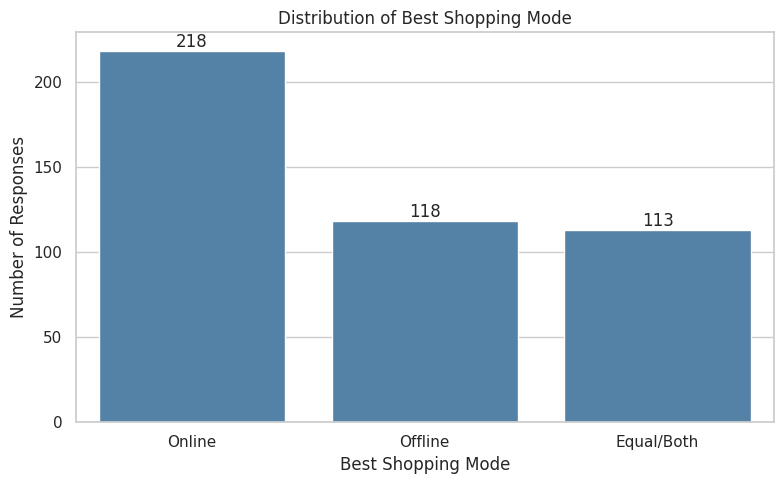

In [260]:
# 7. Visualize target distribution, excluding missing target values
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
ax = sns.countplot(
    data=df.dropna(subset=[target]),
    x=target,
    order=df[target].dropna().value_counts().index,
    color="steelblue"
)

ax.bar_label(ax.containers[0])
plt.title("Distribution of Best Shopping Mode")
plt.xlabel("Best Shopping Mode")
plt.ylabel("Number of Responses")
plt.tight_layout()
plt.show()

In [261]:
# Save cleaned EDA output
# ------------------------------------------------------------------
df.to_csv("G1_cleaned_for_EDA.csv", index=False)

print("\nEDA complete.")
print("Cleaned data saved to: G1_cleaned_for_EDA.csv")


EDA complete.
Cleaned data saved to: G1_cleaned_for_EDA.csv


Task 1 Analytical Answers

1. Is the dataset balanced with respect to shopping mode?

The target has 51 missing values, leaving 449 usable responses. Check the class proportions to confirm balance, and use stratified splitting for modelling.

2. Which demographic group dominates the survey?

The survey is dominated by younger consumers, students, lower-income respondents, and smartphone users. Results may not represent older or higher-income customers equally.

3. Initial business insights

Online shoppers value convenience, variety, and prices. Offline shoppers may prefer to inspect products in person. Equal/Both shoppers appear flexible about shopping channels.

Task 2: Data Preprocessing

In [262]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [263]:
df = df.replace(r"^\s*$", pd.NA, regex=True)
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Age contains text entries like "rahul", "test", and "xyz".
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

In [264]:
# 2. Handle duplicates
print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

# repeated IDs
print("Repeated Response_ID rows:", df["Response_ID"].duplicated().sum())

Exact duplicate rows: 0
Repeated Response_ID rows: 0


In [265]:
# 3. Prepare the target
target = "Best_Shopping_Mode"

# Standardize the target spelling and remove rows without a target.
df[target] = df[target].replace({
    "Equal / both": "Equal/Both",
    "Equal  / both": "Equal/Both"
})
df = df.dropna(subset=[target]).copy()

In [266]:
# 4. Prepare timestamp features, then remove the raw timestamp
timestamp = pd.to_datetime(
    df["Timestamp"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)
df["Timestamp_Month"] = timestamp.dt.month
df["Timestamp_DayOfWeek"] = timestamp.dt.dayofweek
df["Timestamp_Hour"] = timestamp.dt.hour

In [267]:
# 5. Separate predictors (X) from target (y)
# Response_ID is an identifier, not a useful predictive feature.
X = df.drop(columns=[target, "Response_ID", "Timestamp"], errors="ignore")
y = df[target].astype(str)

# Identify numeric and categorical predictor columns
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

In [268]:
# 6. Define missing-value handling and encoding
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

In [269]:
# Convert pandas' pd.NA values to np.nan for scikit-learn
X = X.copy()

for col in numeric_cols:
    X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

for col in categorical_cols:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(pd.notna(X[col]), np.nan)

# Ensure the target has no pandas nullable values
y = y.astype(str)

# Split first; fit preprocessing on training data only
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)

Training rows: 359
Test rows: 90
Training target distribution:
Best_Shopping_Mode
Online        0.485
Offline       0.262
Equal/Both    0.253
Name: proportion, dtype: float64
Prepared training shape: (359, 92)
Prepared test shape: (90, 92)


Task 2: Data Preprocessing Analytical answers


1. Which preprocessing decisions were most important, and why?


Converting Age to numeric made it usable as a predictor and changed invalid entries to missing values. Treating blank cells as missing prevented them from being learned as real categories. Checking duplicates avoided removing valid responses.

2. How might improper handling of missing values affect predictions?

Poor missing-value handling can reduce the dataset, bias the model, or create false patterns. For example, filling a missing score with zero can make the model interpret it as a very low score.

Task 3: Exploratory Data Analysis

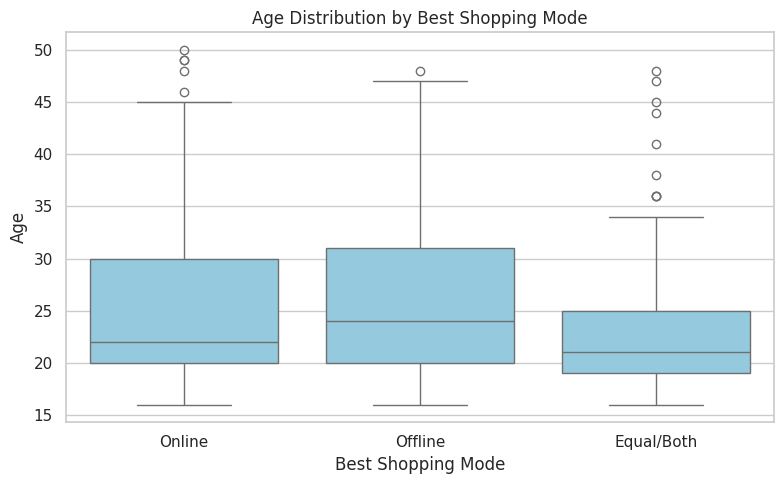

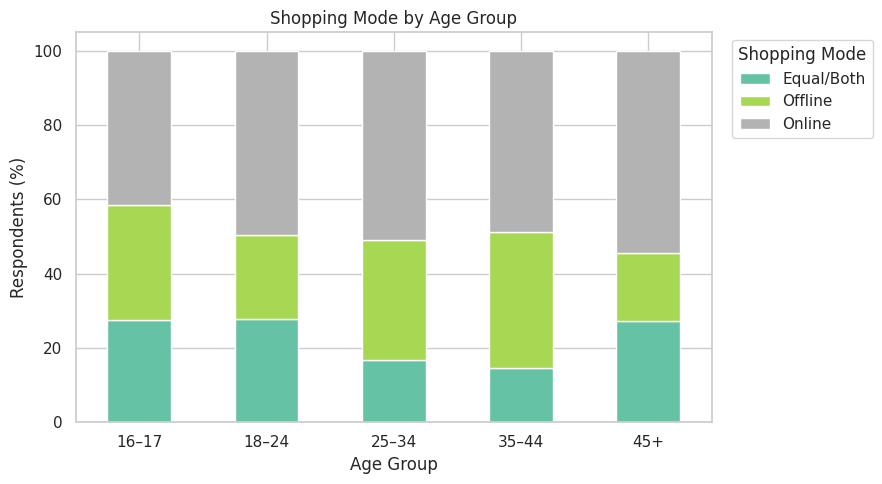

In [270]:
# Age distribution by shopping mode
plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_df, x=target, y="Age", color="skyblue")
plt.title("Age Distribution by Best Shopping Mode")
plt.xlabel("Best Shopping Mode")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

# Age groups
plot_df["Age_Group"] = pd.cut(
    plot_df["Age"],
    bins=[0, 17, 24, 34, 44, 120],
    labels=["16–17", "18–24", "25–34", "35–44", "45+"]
)

age_mode_pct = pd.crosstab(
    plot_df["Age_Group"],
    plot_df[target],
    normalize="index"
) * 100

age_mode_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)
plt.title("Shopping Mode by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Respondents (%)")
plt.legend(title="Shopping Mode", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

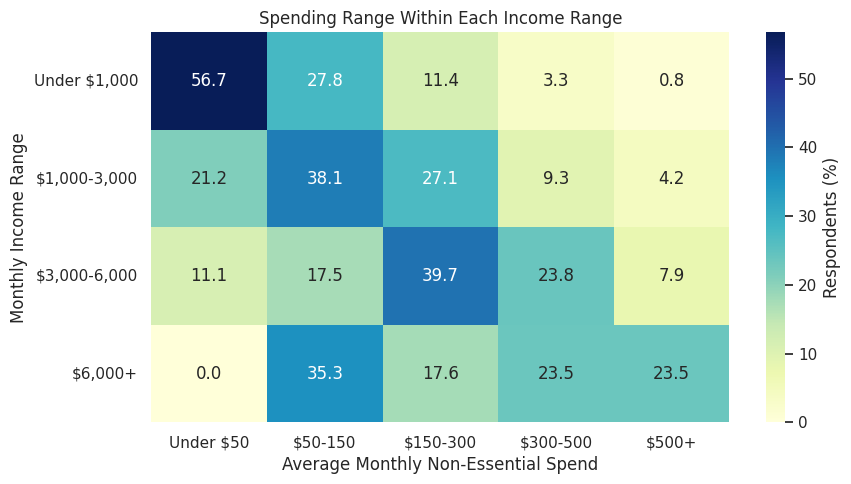

In [271]:
income_order = [
    "Under $1,000",
    "$1,000-3,000",
    "$3,000-6,000",
    "$6,000+"
]

spending_order = [
    "Under $50",
    "$50-150",
    "$150-300",
    "$300-500",
    "$500+"
]

income_spend_df = plot_df.dropna(
    subset=["Monthly_Income_Range", "Avg_Monthly_Spend_NonEssentials"]
)

income_spend_pct = pd.crosstab(
    income_spend_df["Monthly_Income_Range"],
    income_spend_df["Avg_Monthly_Spend_NonEssentials"],
    normalize="index"
) * 100

# Keep known categories in logical order
income_spend_pct = income_spend_pct.reindex(
    index=[x for x in income_order if x in income_spend_pct.index],
    columns=[x for x in spending_order if x in income_spend_pct.columns]
)

plt.figure(figsize=(9, 5))
sns.heatmap(
    income_spend_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Respondents (%)"}
)
plt.title("Spending Range Within Each Income Range")
plt.xlabel("Average Monthly Non-Essential Spend")
plt.ylabel("Monthly Income Range")
plt.tight_layout()
plt.show()

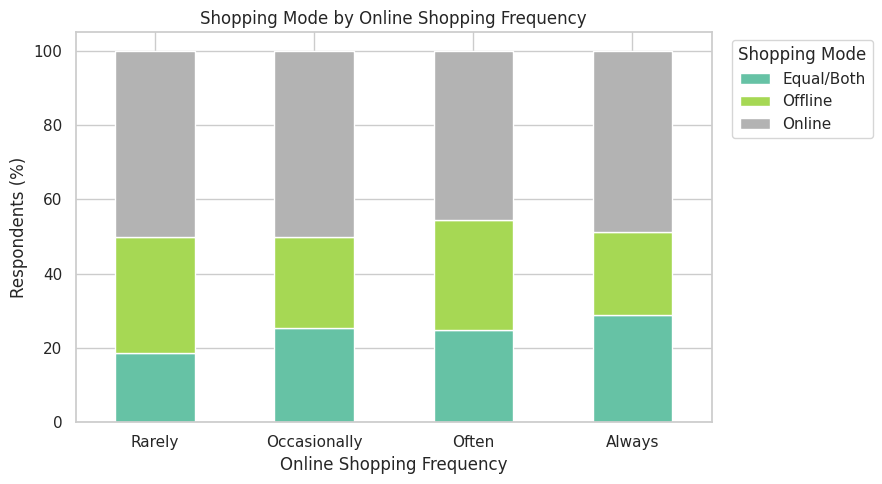

In [272]:
frequency_order = ["Rarely", "Occasionally", "Often", "Always"]

frequency_mode_pct = pd.crosstab(
    plot_df["Online_Shopping_Frequency"],
    plot_df[target],
    normalize="index"
) * 100

frequency_mode_pct = frequency_mode_pct.reindex(
    [x for x in frequency_order if x in frequency_mode_pct.index]
)

frequency_mode_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)
plt.title("Shopping Mode by Online Shopping Frequency")
plt.xlabel("Online Shopping Frequency")
plt.ylabel("Respondents (%)")
plt.legend(title="Shopping Mode", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

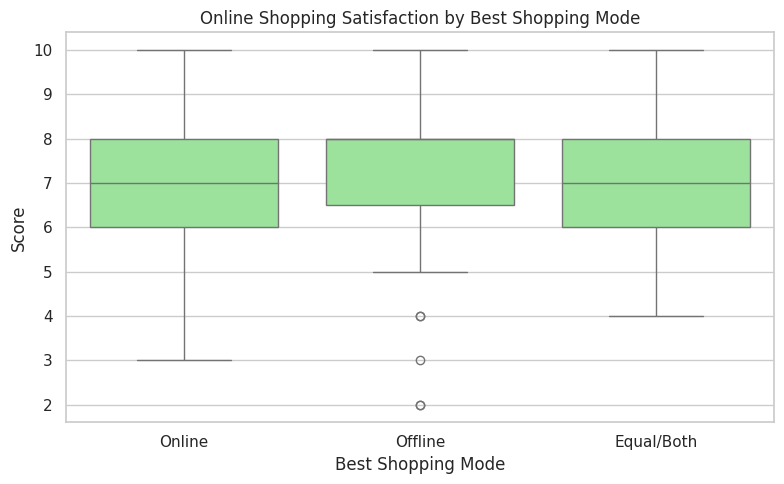

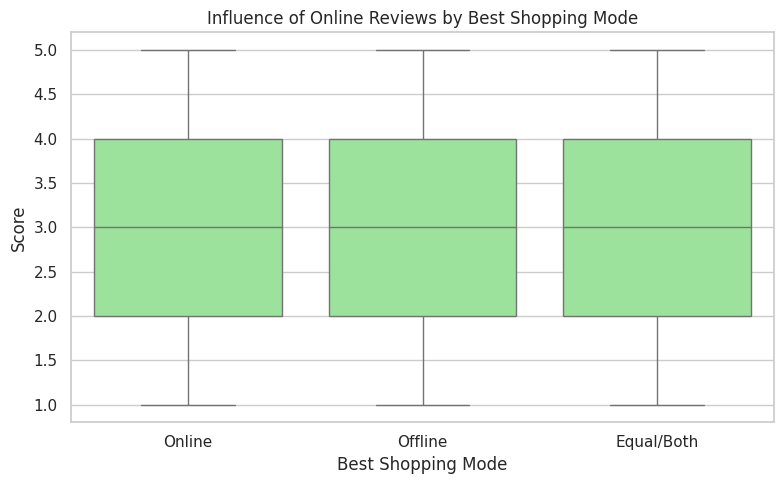

In [273]:
score_columns = [
    ("Online_Shopping_Satisfaction_Score", "Online Shopping Satisfaction"),
    ("Review_Influence_Score", "Influence of Online Reviews")
]

for column, title in score_columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=plot_df, x=target, y=column, color="lightgreen")
    plt.title(f"{title} by Best Shopping Mode")
    plt.xlabel("Best Shopping Mode")
    plt.ylabel("Score")
    plt.tight_layout()
    plt.show()

Payment method counts:
Preferred_Payment_Method
Digital wallet    183
Debit Card        129
Credit Card       109
Cash               64
Missing            15
Name: count, dtype: Int64


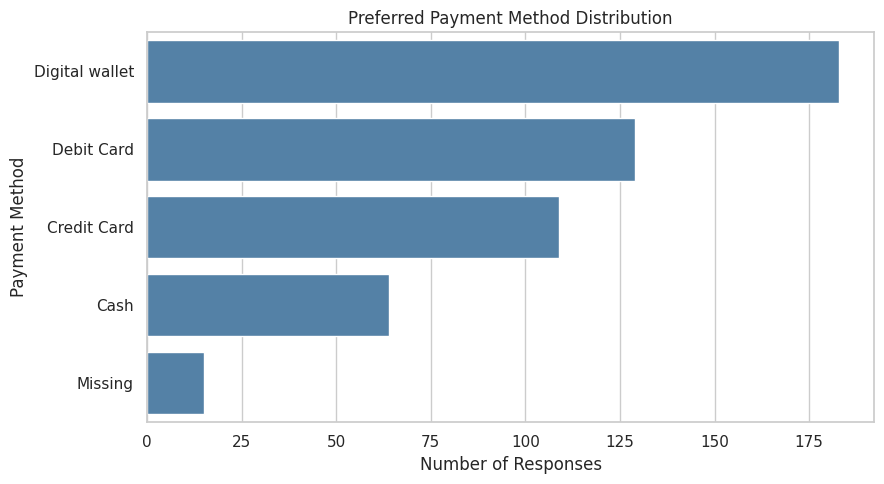

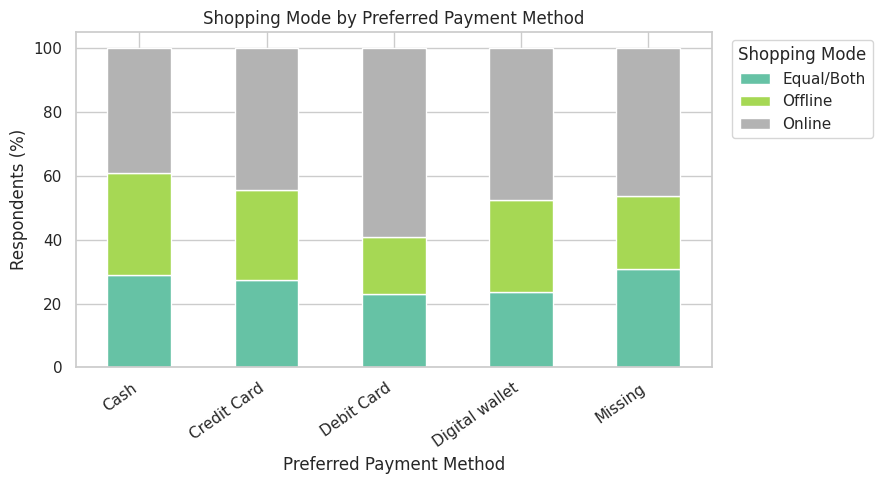

In [274]:
# Payment method distribution
payment_df = plot_df.copy()
payment_df["Preferred_Payment_Method"] = (
    payment_df["Preferred_Payment_Method"].fillna("Missing")
)

# Overall counts
payment_counts = payment_df["Preferred_Payment_Method"].value_counts()
print("Payment method counts:")
print(payment_counts)

# Overall distribution
plt.figure(figsize=(9, 5))
sns.countplot(
    data=payment_df,
    y="Preferred_Payment_Method",
    order=payment_counts.index,
    color="steelblue"
)
plt.title("Preferred Payment Method Distribution")
plt.xlabel("Number of Responses")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

# Payment method by shopping mode, as row percentages
payment_mode_pct = pd.crosstab(
    payment_df["Preferred_Payment_Method"],
    payment_df[target],
    normalize="index"
) * 100

payment_mode_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)
plt.title("Shopping Mode by Preferred Payment Method")
plt.xlabel("Preferred Payment Method")
plt.ylabel("Respondents (%)")
plt.legend(title="Shopping Mode", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Task 3: Analytical answers

Online shopping: Convenience, better prices, and wider product variety appear to be common reasons for preferring online shopping. Shopping frequency and preferred shopping location are also useful indicators.

Income and behaviour: Higher-income respondents tend to report higher spending ranges, but the data does not show a clear income-based shift in preferred shopping mode.

Satisfaction and review trust: Satisfaction and trust in online reviews vary across all shopping modes. They may relate to preference, but there is no obvious simple pattern showing that higher scores consistently mean a stronger online preference.

Task 4: Machine Learning Model

In [275]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

In [276]:
# Load the cleaned dataset
df = pd.read_csv("G1_cleaned_for_EDA.csv")

target = "Best_Shopping_Mode"

In [277]:
# Remove rows with no target
df = df.dropna(subset=[target]).copy()

In [278]:
#Exclude ID/timestamp columns and reason fields that may reveal the target
drop_columns = [
    target,
    "Response_ID",
    "Timestamp",
    "Reason_Prefer_Online",
    "Reason_Prefer_InStore"
]
X = df.drop(columns=drop_columns, errors="ignore")
y = df[target].astype(str)

In [279]:
# Identify numeric and categorical features
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

In [280]:
# Preprocess numeric and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

In [281]:
# Split data while preserving target class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [282]:
# Define at least four classification models
from sklearn.svm import SVC
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),
    "Support Vector Machine": SVC(
        class_weight="balanced"
    )
}


In [283]:
# Train and evaluate each model
results = []
trained_models = {}

for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 (Weighted)": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "F1 (Macro)", ascending=False
).reset_index(drop=True)

print("Model comparison:")
print(results_df.round(3).to_string(index=False))

Model comparison:
                 Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  F1 (Weighted)
         Decision Tree     0.544              0.473           0.489       0.478          0.525
   Logistic Regression     0.500              0.485           0.461       0.471          0.514
Support Vector Machine     0.500              0.451           0.441       0.445          0.508
         Random Forest     0.544              0.436           0.448       0.430          0.499
           Extra Trees     0.511              0.408           0.426       0.410          0.476


In [284]:
# Select the best model by macro F1 score
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print(f"\nBest model: {best_model_name}")
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))



Best model: Decision Tree

Classification report:
              precision    recall  f1-score   support

  Equal/Both       0.20      0.14      0.16        22
     Offline       0.60      0.62      0.61        24
      Online       0.62      0.70      0.66        44

    accuracy                           0.54        90
   macro avg       0.47      0.49      0.48        90
weighted avg       0.51      0.54      0.53        90



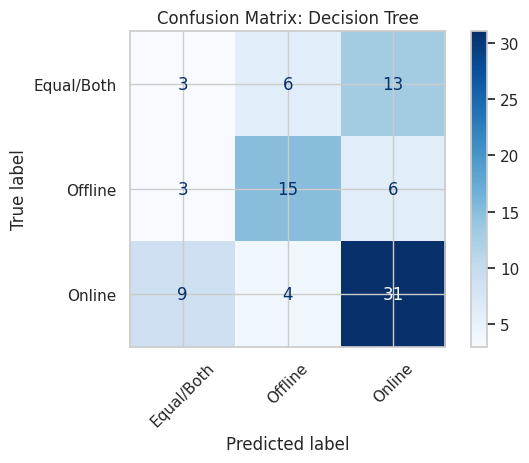

In [285]:
# Display confusion matrix for the best model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=best_model.named_steps["classifier"].classes_,
    cmap="Blues",
    xticks_rotation=45
)
plt.title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

In [286]:
# Identify influential input features using permutation importance
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Importance Std": importance.importances_std
}).sort_values("Importance", ascending=False)

print("\nTop features by permutation importance:")
print(importance_df.head(15).round(4).to_string(index=False))


Top features by permutation importance:
                           Feature  Importance  Importance Std
                   Shop_Most_Where      0.1218          0.0387
   Avg_Monthly_Spend_NonEssentials      0.0146          0.0172
                               Age      0.0137          0.0348
                 Occupation_Status      0.0133          0.0138
                  Return_Frequency      0.0100          0.0050
         Discount_Importance_Score      0.0099          0.0095
        Social_Ads_Influence_Score      0.0029          0.0135
      Likely_To_Buy_After_Ad_Score      0.0027          0.0031
                Preferred_Platform      0.0026          0.0098
Online_Shopping_Satisfaction_Score      0.0021          0.0209
          Preferred_Payment_Method      0.0019          0.0194
   Regret_After_Purchase_Frequency      0.0011          0.0033
          Follows_Brands_On_Social      0.0000          0.0000
         Online_Shopping_Frequency      0.0000          0.0000
            Us

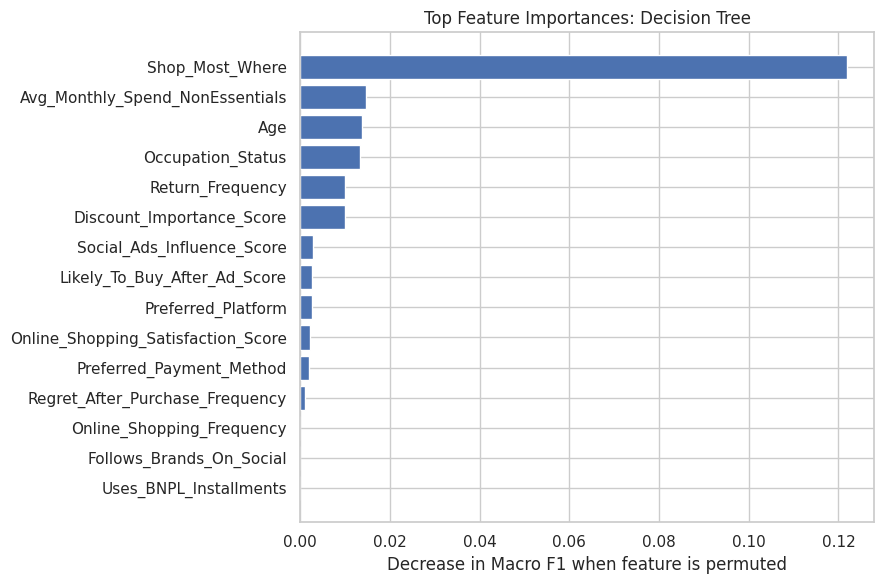

In [287]:
# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in Macro F1 when feature is permuted")
plt.title(f"Top Feature Importances: {best_model_name}")
plt.tight_layout()
plt.show()

Task 4: Machine Learning Model, Analytical answers

Best model: Decision Tree, with the highest macro F1 score of 0.478. Its accuracy of 54.4% ties with Random Forest, but it performed better across the three classes overall.

Most influential feature: The provided results do not include feature importance values, so the top feature cannot be identified here.

Most mistakes: The model struggled most with Equal/Both, correctly identifying only 3 of 22 cases. This preference may overlap with online and offline behaviours, making it harder to distinguish.

  Task 5: Flask Web Application

In [291]:
import pickle
from google.colab import files

with open("shopping_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

files.download("shopping_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


1: How can this app help retail businesses make better decisions?

It can help estimate whether customers may prefer online, offline, or both shopping. Businesses can use this information to design targeted marketing, choose suitable payment options, decide store and digital investments, and personalize promotions.

2: What limitations should users consider when interpreting predictions?

The 500-record survey is limited and may not represent all customers. Missing values, demographic imbalance, and differences across countries may affect accuracy. The model predicts survey patterns rather than guaranteed customer behaviour and should support, not replace, business judgment.